In [1]:
# !pip install tensorflow 
# !pip install tensorflow_datasets 

In [2]:
import tensorflow as tf
import tensorflow_datasets as tfds
import numpy as np

In [3]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

In [4]:
tf.random.set_seed(1234)

Data Import and Preprocessing

In [5]:
(d_train, d_test)= tfds.load('cifar10', split=['train', 'test'], as_supervised=True, shuffle_files=True)

In [6]:
d_train.take(1)

<_TakeDataset element_spec=(TensorSpec(shape=(32, 32, 3), dtype=tf.uint8, name=None), TensorSpec(shape=(), dtype=tf.int64, name=None))>

In [7]:
x_train = np.array([])
y_train = np.array([])

In [8]:
x_test = np.array([])
y_test = np.array([])
x_test = np.array([np.array(x) for x, y in d_test.as_numpy_iterator()])
y_test = np.array([np.array(y) for x, y in d_test.as_numpy_iterator()])

In [9]:
x_train
y_train

array([], dtype=float64)

In [10]:
x_train = np.array([np.array(x) for x, y in d_train.as_numpy_iterator()])
y_train = np.array([np.array(y) for x, y in d_train.as_numpy_iterator()])

Data Visualization and Manual Inspection

In [11]:
x_train.shape

(50000, 32, 32, 3)

In [12]:
y_train.shape

(50000,)

In [13]:
def print_img(img):
    # img = mpimg.imread('your_image.png')
    imgplot = plt.imshow(img)
    plt.show()

(32, 32, 3)
7


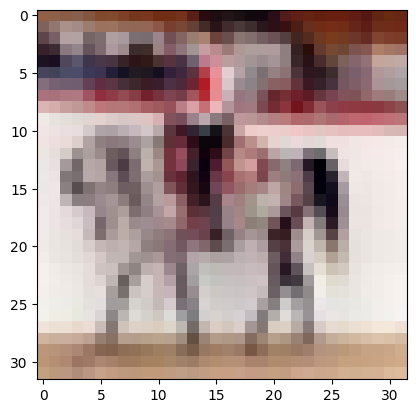

In [14]:
for e in tfds.as_numpy(d_train.take(1)):
    image, label = e
    print(image.shape)
    print(label)
    print_img(image)

In [15]:
def normalize_img(image, label):
  return tf.cast(image, tf.float32) / 255., label

d_train = d_train.map(normalize_img)
d_train = d_train.shuffle(1024)
d_train = d_train.batch(128)

In [16]:
d_train

<_BatchDataset element_spec=(TensorSpec(shape=(None, 32, 32, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.int64, name=None))>

(128, 32, 32, 3)
[5 8 9 8 1 7 5 8 2 3 3 5 5 7 3 8 6 8 1 7 4 9 3 3 4 6 2 8 6 1 6 0 1 7 2 3 2
 8 1 5 9 7 3 7 3 7 2 1 5 5 0 5 7 0 4 8 3 4 2 1 1 6 3 5 1 2 3 9 8 5 4 0 7 5
 3 9 6 1 3 2 3 7 5 2 5 7 4 7 0 0 2 5 4 8 4 0 6 7 6 2 7 2 5 3 0 5 4 7 5 3 3
 2 3 7 4 8 7 8 0 1 5 2 3 9 0 0 1 9]


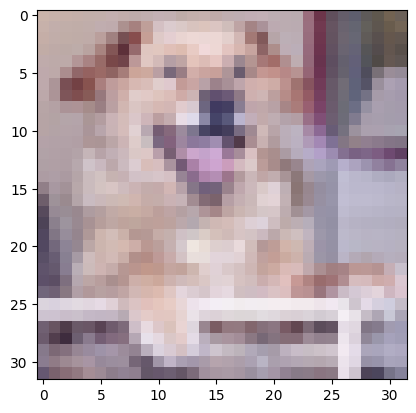

5


In [17]:
for e in tfds.as_numpy(d_train.take(1)):
    # 1 whole batch of 128 images and labels
    image, label = e
    print(image.shape)
    print(label)
    print_img(image[0])  # print the first image in the batch
    print(label[0])

In [18]:
d_test = d_test.map(normalize_img)
d_test = d_test.batch(128)


(128, 32, 32, 3)
[7 0 6 9 5 1 7 0 3 2 7 2 7 9 6 8 8 8 7 9 4 2 3 5 0 0 2 8 1 8 2 0 7 2 0 0 9
 1 0 5 1 5 0 3 5 0 2 0 5 3 7 4 1 4 2 5 1 5 2 0 7 2 2 1 8 5 3 5 3 0 6 1 5 2
 8 2 5 3 0 8 8 8 6 5 8 1 9 8 1 3 6 0 8 7 5 3 1 8 1 4 0 8 7 3 4 1 4 3 2 2 1
 4 7 4 9 3 4 4 2 8 1 2 8 5 2 4 0 5]


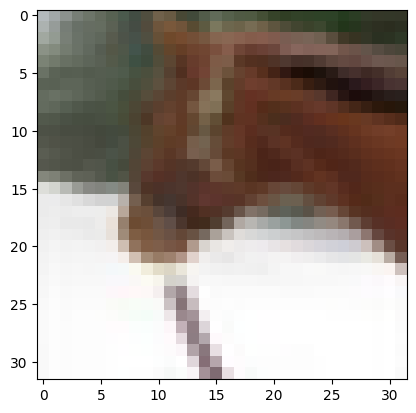

7


In [19]:
for e in tfds.as_numpy(d_test.take(1)):
    # 1 whole batch of 128 images and labels
    image, label = e
    print(image.shape)
    print(label)
    print_img(image[0])  # print the first image in the batch
    print(label[0])

In [20]:
x_train = x_train.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0

Autoencoder Model 

In [21]:
inputLayer = tf.keras.layers.Input(shape=(32,32,3), dtype=tf.float32, name='input_layer')
x = tf.keras.Sequential([tf.keras.layers.RandomFlip("horizontal"), tf.keras.layers.RandomZoom(0.1),tf.keras.layers.RandomTranslation(0.1,0.1)])(inputLayer)
x = tf.keras.layers.Conv2D(32,(3,3),activation='relu', padding='same')(x)
x = tf.keras.layers.BatchNormalization()(x)
x = tf.keras.layers.MaxPool2D((2,2), padding='same')(x)
x = tf.keras.layers.Dropout(0.2)(x)

x = tf.keras.layers.Conv2D(64,(3,3),activation='relu', padding='same')(x)
x = tf.keras.layers.BatchNormalization()(x)
x = tf.keras.layers.MaxPool2D((2,2), padding='same')(x)
x = tf.keras.layers.Dropout(0.2)(x)


x = tf.keras.layers.Conv2D(128,(3,3),activation='relu', padding='same')(x)
x = tf.keras.layers.BatchNormalization()(x)
encoder_out = tf.keras.layers.MaxPool2D((2,2), padding='same')(x)
x = tf.keras.layers.Dropout(0.2)(x)


x = tf.keras.layers.Conv2D(128,(3,3),activation='relu', padding='same')(encoder_out)
x = tf.keras.layers.UpSampling2D((2,2))(x)
x = tf.keras.layers.Conv2D(64,(3,3),activation='relu', padding='same')(x)
x = tf.keras.layers.UpSampling2D((2,2))(x)
x = tf.keras.layers.Conv2D(32,(3,3),activation='relu', padding='same')(x)
x = tf.keras.layers.UpSampling2D((2,2))(x)
decoder_out = tf.keras.layers.Conv2D(3,(3,3),activation='sigmoid', padding='same')(x)
autoencoder = tf.keras.Model(inputLayer, decoder_out)


In [22]:
autoencoder.compile(optimizer='adam', loss='mse')

In [23]:
autoencoder.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential (Sequential)         │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 4, 4, 128)      │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d (UpSampling2D)    │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 8, 8, 64)       │        73,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_1 (UpSampling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 16, 16, 32)     │        18,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_2 (UpSampling2D)  │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 32, 32, 3)      │           867 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 334,851 (1.28 MB)

 Trainable params: 334,403 (1.28 MB)

 Non-trainable params: 448 (1.75 KB)

In [24]:
autoencoder.fit(x=x_train,y=x_train,batch_size=128, epochs=10, validation_data=(x_test, x_test))

Epoch 1/10
391/391 ━━━━━━━━━━━━━━━━━━━━ 105s 258ms/step - loss: 0.0297 - val_loss: 0.0316
Epoch 2/10
391/391 ━━━━━━━━━━━━━━━━━━━━ 104s 264ms/step - loss: 0.0265 - val_loss: 0.0222
Epoch 3/10
391/391 ━━━━━━━━━━━━━━━━━━━━ 107s 273ms/step - loss: 0.0259 - val_loss: 0.0213
Epoch 4/10
391/391 ━━━━━━━━━━━━━━━━━━━━ 102s 261ms/step - loss: 0.0255 - val_loss: 0.0225
Epoch 5/10
391/391 ━━━━━━━━━━━━━━━━━━━━ 103s 263ms/step - loss: 0.0253 - val_loss: 0.0204
Epoch 6/10
391/391 ━━━━━━━━━━━━━━━━━━━━ 98s 251ms/step - loss: 0.0251 - val_loss: 0.0207
Epoch 7/10
391/391 ━━━━━━━━━━━━━━━━━━━━ 97s 249ms/step - loss: 0.0250 - val_loss: 0.0207
Epoch 8/10
391/391 ━━━━━━━━━━━━━━━━━━━━ 96s 245ms/step - loss: 0.0248 - val_loss: 0.0199
Epoch 9/10
391/391 ━━━━━━━━━━━━━━━━━━━━ 98s 252ms/step - loss: 0.0246 - val_loss: 0.0207
Epoch 10/10
391/391 ━━━━━━━━━━━━━━━━━━━━ 97s 247ms/step - loss: 0.0245 - val_loss: 0.0213


Classification Model with encoder head frozen

In [36]:

classification_layer = tf.keras.layers.Conv2D(32,(2,2), activation='relu', name='classification_layer')(encoder_out)
flatLayer = tf.keras.layers.Flatten()(classification_layer)
classifier_out = tf.keras.layers.Dense(128, activation='relu')(flatLayer)
x = tf.keras.layers.Dropout(0.2)(classifier_out)
classifier_out = tf.keras.layers.Dense(10, activation='softmax')(x)
classifier = tf.keras.Model(inputLayer, classifier_out)

In [37]:
classifier.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])


In [38]:
classifier.summary()

Model: "functional_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential (Sequential)         │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ classification_layer (Conv2D)   │ (None, 3, 3, 32)       │        16,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 288)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │        36,992 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 148,842 (581.41 KB)

 Trainable params: 54,698 (213.66 KB)

 Non-trainable params: 94,144 (367.75 KB)

In [39]:
autoencoder.trainable = False

In [40]:
classifier.fit(x=x_train,y=y_train,batch_size=128, epochs=50, validation_data=(x_test, y_test))

Epoch 1/50
391/391 ━━━━━━━━━━━━━━━━━━━━ 27s 63ms/step - accuracy: 0.5929 - loss: 1.1518 - val_accuracy: 0.6771 - val_loss: 0.9652
Epoch 2/50
391/391 ━━━━━━━━━━━━━━━━━━━━ 23s 60ms/step - accuracy: 0.6908 - loss: 0.8810 - val_accuracy: 0.7200 - val_loss: 0.8147
Epoch 3/50
391/391 ━━━━━━━━━━━━━━━━━━━━ 24s 62ms/step - accuracy: 0.7118 - loss: 0.8229 - val_accuracy: 0.7204 - val_loss: 0.8336
Epoch 4/50
391/391 ━━━━━━━━━━━━━━━━━━━━ 23s 60ms/step - accuracy: 0.7233 - loss: 0.7899 - val_accuracy: 0.7198 - val_loss: 0.8492
Epoch 5/50
391/391 ━━━━━━━━━━━━━━━━━━━━ 22s 57ms/step - accuracy: 0.7303 - loss: 0.7731 - val_accuracy: 0.7224 - val_loss: 0.8525
Epoch 6/50
391/391 ━━━━━━━━━━━━━━━━━━━━ 22s 57ms/step - accuracy: 0.7337 - loss: 0.7560 - val_accuracy: 0.7440 - val_loss: 0.7752
Epoch 7/50
391/391 ━━━━━━━━━━━━━━━━━━━━ 25s 64ms/step - accuracy: 0.7418 - loss: 0.7405 - val_accuracy: 0.7444 - val_loss: 0.7792
Epoch 8/50
391/391 ━━━━━━━━━━━━━━━━━━━━ 25s 63ms/step - accuracy: 0.7432 - loss: 0.7379 - 